# Segmentación multietapa de una nube de puntos industrial 3D

En este trabajo se combinan agrupamiento no supervisado y criterios geométricos para separar las superficies y estructuras de una instalación industrial. Se emplean las coordenadas, los colores y las normales de los puntos, avanzando desde las superficies extensas hacia regiones más pequeñas y tramos cilíndricos.

El notebook presenta los datos, los experimentos y el resultado del método completo. Las celdas cargan y analizan las salidas conservadas del proyecto. Las instrucciones para recalcular la segmentación se encuentran en el README.

## 1. Introducción y objetivos

Una nube de puntos representa superficies mediante muestras en el espacio. Su organización no indica directamente qué puntos forman una columna, una cubierta o una conducción. El objetivo es obtener una partición razonable de la escena y asignar categorías únicamente cuando existan argumentos geométricos suficientes.

Buscamos distinguir las estructuras principales, separar regiones próximas y mejorar la continuidad de los conductos rectos. También conservamos las coordenadas, el orden y los atributos originales. La segmentación se calcula en una representación reducida y luego se transfiere a todos los puntos de entrada.

Distinguimos dos resultados. La **segmentación por instancias** asigna un identificador a cada región; una región puede ser una parte de un objeto. La **clasificación semántica parcial** asigna categorías como piso o superficie plana. Tener una instancia no implica conocer su clase. El identificador de instancia -1 indica ausencia de región y la clase 0 corresponde a unknown.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
OUTPUTS = ROOT / "outputs"
METRICS = OUTPUTS / "metrics"
EXPERIMENTS = OUTPUTS / "experiments"
FIGURES = OUTPUTS / "figures"


def leer_json(nombre):
    return json.loads((METRICS / nombre).read_text(encoding="utf-8"))


def mostrar_figura(nombre, descripcion):
    display(Image(filename=str(FIGURES / nombre), width=1000))
    display(Markdown(f"*{descripcion}*"))


eda = leer_json("eda.json")
resultado = leer_json("final.json")
segmentos = pd.read_csv(OUTPUTS / "segments.csv")
clases = pd.read_csv(METRICS / "semantic_summary.csv")

## 2. Fundamentos de segmentación 3D

### Posición, color y normales

Cada punto tiene una posición $\mathbf{x}_i=(x_i,y_i,z_i)$, un color RGB y una normal. La normal describe una dirección perpendicular a la superficie local. Dos caras que se encuentran en una esquina pueden estar muy próximas, pero tener normales diferentes. El color ayuda a detectar algunas discontinuidades, aunque también varía por sombras o condiciones del escaneo.

La distancia espacial utilizada es

$$d_{ij}=\|\mathbf{x}_i-\mathbf{x}_j\|_2.$$

No concatenamos directamente XYZ, RGB y normales en una sola distancia: sus unidades y escalas son distintas. La geometría se compara en unidades del escáner, el color se expresa en $[0,1]$, los ángulos en grados y la curvatura aproximada es adimensional.

### Vecinos y conectividad

Los vecinos próximos permiten describir una superficie y comprobar si dos regiones tienen contacto. Un árbol KD acelera estas consultas. Sin embargo, la cercanía no demuestra que dos muestras pertenezcan al mismo objeto: una tubería puede apoyarse sobre una estructura y una viga puede tocar una columna. Por eso combinamos conectividad con orientación, forma y continuidad.

El enfoque es no supervisado porque no se entrenó un clasificador con etiquetas de referencia. Los grupos se obtienen de los datos y una parte de su significado se interpreta mediante reglas geométricas. Esto no equivale a un modelo semántico entrenado.

## 3. Descripción de la nube de puntos

El archivo de trabajo es FARO_Scan_Full_Sub1_down3_with_normals.ply. Contiene 1.647.021 puntos y está almacenado en formato PLY binario little endian. Las coordenadas XYZ y las normales son float32; los colores son tres valores uint8 entre 0 y 255.

No se encontraron coordenadas duplicadas ni valores no finitos. Se detectaron dos normales nulas, por lo que las normalizaciones protegen las divisiones por cero. Los atributos originales se conservan también en las salidas; únicamente el RGB utilizado para mostrar la segmentación se sustituye por colores de instancia o clase.

No existe un metadato que certifique que las coordenadas estén en metros. Por ello usamos u, unidades de coordenadas. Tampoco se tomó automáticamente Z como vertical: primero se revisaron distribuciones, normales y proyecciones, y después se contrastó esa interpretación con las superficies extraídas.

In [2]:
resumen_datos = pd.DataFrame({
    "Propiedad": ["Puntos", "XYZ no finitos", "RGB no finitos", "Normales no finitas", "XYZ duplicados", "Normales nulas"],
    "Valor": [eda["n_points"], eda["invalid_xyz"], eda["invalid_rgb"], eda["invalid_normals"], eda["duplicate_xyz"], eda["zero_normals"]],
})
display(resumen_datos)
display(pd.DataFrame({
    "Eje": ["X", "Y", "Z"],
    "Mínimo (u)": eda["bbox_min"],
    "Máximo (u)": eda["bbox_max"],
    "Extensión (u)": eda["dimensions"],
}).round(4))

,Propiedad,Valor
0,Puntos,1647021
1,XYZ no finitos,0
2,RGB no finitos,0
3,Normales no finitas,0
4,XYZ duplicados,0
5,Normales nulas,2


,Eje,Mínimo (u),Máximo (u),Extensión (u)
0,X,-2.5822,28.8035,31.3857
1,Y,-11.8736,22.9943,34.8679
2,Z,-2.3112,14.4591,16.7702


### Convenciones de visualización

Las vistas tridimensionales utilizan proyección ortográfica: no hay reducción aparente del tamaño con la distancia a la cámara. Las imágenes generales de las etapas mantienen la misma cámara, orientación, escala y encuadre para facilitar su comparación. Las distancias se expresan en unidades del escáner (u), porque no se confirmó que fueran metros. Z se interpreta como vertical aproximada a partir de la geometría observada, no de un metadato de orientación. Estas convenciones se aplican a las figuras del trabajo y se explican aquí para evitar repetirlas en cada imagen.

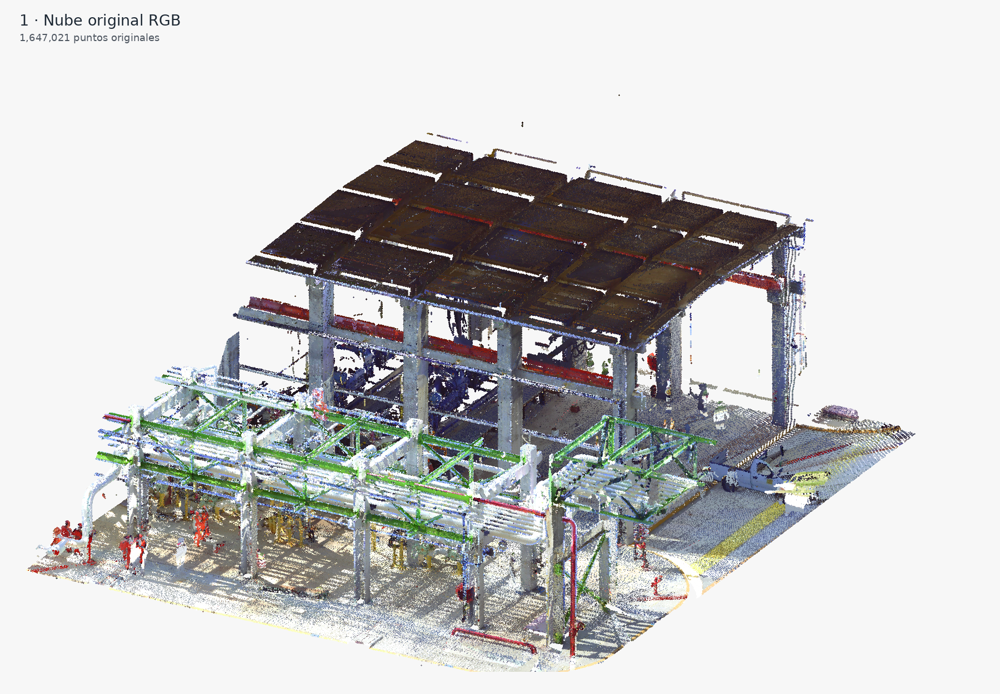

*Nube original con RGB real. Esta cámara se conserva en las figuras generales de las etapas del método.*

In [3]:
mostrar_figura('01_original.png', 'Nube original con RGB real. Esta cámara se conserva en las figuras generales de las etapas del método.')

## 4. Análisis exploratorio

La escena ocupa aproximadamente 31,39 × 34,87 × 16,77 u. Las distribuciones de altura muestran varias acumulaciones, compatibles con superficies horizontales en diferentes niveles. El RGB permite reconocer visualmente redes y soportes, pero no se convierte directamente en una clase: compartir color no demuestra compartir función.

Las distancias a vecinos se obtuvieron mediante 60.000 consultas reproducibles al árbol de la nube completa, con semilla 42. No se calcularon sobre una muestra más dispersa usada como sustituto de la nube. La mediana al primer vecino es aproximadamente 0,03355 u, y al octavo vecino es 0,06502 u. Estas escalas ayudan a escoger radios y tamaños de voxel.

La mayoría de normales vecinas tienen orientaciones compatibles. Un pequeño porcentaje tiene signos opuestos; la normal de una misma superficie puede representarse con cualquiera de los dos signos. Por eso se usa el valor absoluto de su producto escalar. La componente vertical dominante y la forma de los soportes respaldan Z como vertical aproximada. La normal del plano dominante lo confirma con una desviación pequeña respecto al eje; esto es una inferencia geométrica, no una medida física de la gravedad.

In [4]:
cuantiles_vecinos = pd.DataFrame(
    eda["distance_quantiles"],
    index=eda["distance_quantile_levels"],
)
cuantiles_vecinos.index.name = "Cuantil"
cuantiles_vecinos.columns = [f"Vecino {columna} (u)" for columna in cuantiles_vecinos.columns]
display(cuantiles_vecinos.round(5))
vertical = leer_json("vertical.json")
display(pd.DataFrame({
    "Eje más próximo": [vertical["nearest_axis"]],
    "Ángulo al eje (grados)": [vertical["angle_to_axis_degrees"]],
    "Normal estimada": [vertical["vector"]],
}))

,Vecino 1 (u),Vecino 4 (u),Vecino 8 (u),Vecino 16 (u)
Cuantil,,,,
0.01,0.03170,0.03505,0.05001,0.06865
0.10,0.03197,0.03838,0.05788,0.07904
0.25,0.03246,0.04095,0.06159,0.08390
0.50,0.03355,0.04429,0.06502,0.08824
0.75,0.03532,0.04856,0.06868,0.09299
0.90,0.03765,0.05415,0.07437,0.10413
0.95,0.03954,0.06012,0.08238,0.11654
0.99,0.04543,0.08310,0.11618,0.16832


,Eje más próximo,Ángulo al eje (grados),Normal estimada
0,Z,0.338731,"[-0.0011921897119719247, 0.005790479487590603,..."


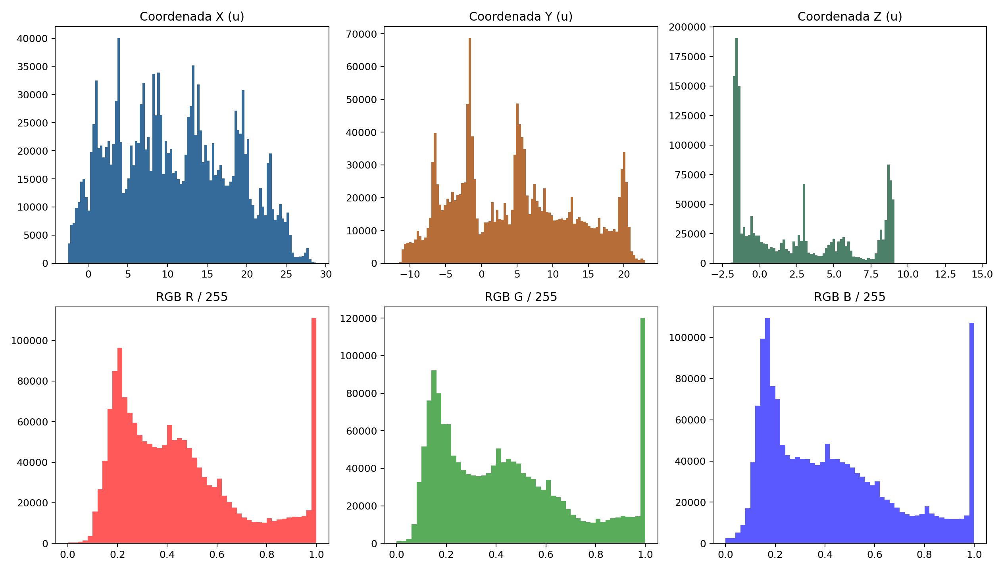

*Distribuciones de posición y RGB del dataset. Los niveles de Z motivan estudiar planos horizontales, sin asignarles una clase por su tamaño.*

In [5]:
mostrar_figura('eda_distribuciones.png', 'Distribuciones de posición y RGB del dataset. Los niveles de Z motivan estudiar planos horizontales, sin asignarles una clase por su tamaño.')

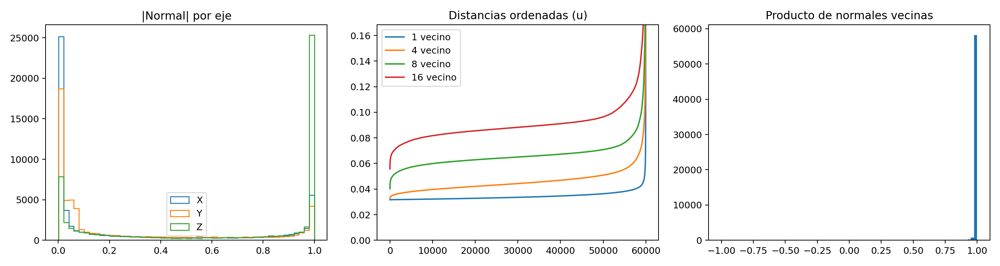

*Orientaciones de normales y distancias características. La cola de distancias altas también puede corresponder a bordes o zonas dispersas válidas.*

In [6]:
mostrar_figura('eda_normales_vecinos.png', 'Orientaciones de normales y distancias características. La cola de distancias altas también puede corresponder a bordes o zonas dispersas válidas.')

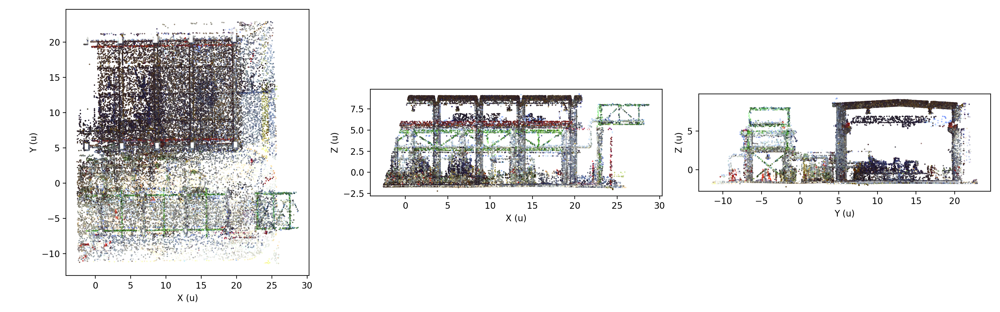

*Proyecciones XY, XZ y YZ. Permiten reconocer cubierta, soportes y redes sin depender de una sola vista tridimensional.*

In [7]:
mostrar_figura('eda_proyecciones.png', 'Proyecciones XY, XZ y YZ. Permiten reconocer cubierta, soportes y redes sin depender de una sola vista tridimensional.')

## 5. Preprocesamiento y correspondencia

### Reducción por voxel

La nube original ya tiene una separación apreciable entre puntos. Aun así, trabajar con todos ellos en cada búsqueda de vecinos resulta costoso. La voxelización divide el espacio en cubos de lado $v$ y calcula un representante por cubo ocupado:

$$\mathbf{k}_i=\left\lfloor\frac{\mathbf{x}_i-\mathbf{o}}{v}\right\rfloor.$$

Los representantes usan coordenadas y colores promediados. El tamaño seleccionado es 0,08 u, que produce 459.991 representantes. Se comparó con 0,06 y 0,12 u: la opción fina conserva más detalle y requiere más procesamiento; la más gruesa puede perder geometría de conductos pequeños. La comparación de resoluciones caracteriza densidad y coste, no demuestra por sí sola mayor precisión de segmentación.

Se evaluaron candidatos a outlier con la media de distancias a 19 vecinos y umbral media + 2 desviaciones, además de un criterio por radio $2v$. No se borraron automáticamente: algunos pertenecen a bordes y zonas dispersas. La nube original permanece completa.

### Transferencia exacta de índices

Para cada fila original se conserva el índice $m(i)$ de su voxel. Al terminar:

$$\ell_i=\widehat{\ell}_{m(i)}.$$

La transferencia no busca simplemente el representante más próximo y no cambia el orden original. Dentro de un mismo voxel no se pueden distinguir superficies que se hayan mezclado al promediar; recuperar todas las filas no recupera ese detalle perdido. Las normales se agregan mediante el tensor promedio $\mathbf{n}\mathbf{n}^T$, para evitar cancelación de signos opuestos.

In [8]:
preprocesamiento = pd.DataFrame(leer_json("preprocessing_comparison.json"))
display(preprocesamiento.rename(columns={
    "voxel": "Voxel (u)", "n": "Representantes", "seconds": "Tiempo (s)",
    "sor_candidates": "Candidatos estadísticos", "radius_isolated": "Candidatos por radio",
}).round(4))

,Voxel (u),Representantes,Tiempo (s),median_neighbor,d8_q90,Candidatos estadísticos,Candidatos por radio
0,0.06,773123,9.2855,0.0477,0.1091,8652,3550
1,0.08,459991,7.6125,0.0645,0.1413,5716,1980
2,0.12,216713,11.0329,0.0927,0.2093,3382,1133


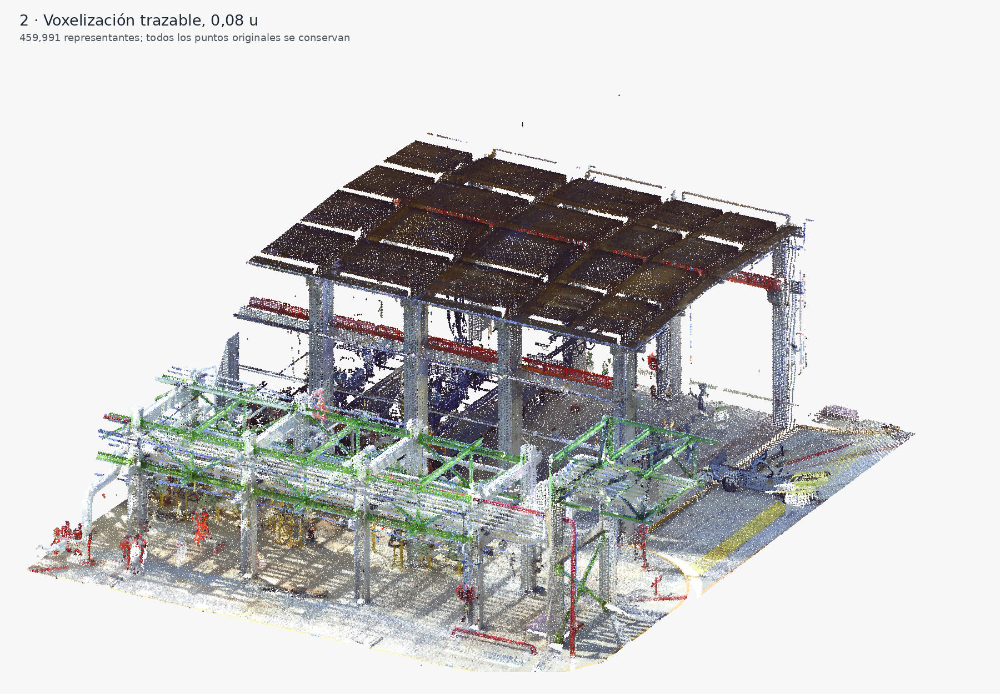

*Nube reducida por voxel. El encuadre es el mismo de la nube original; cambia la densidad de representantes, no la geometría conservada en el archivo de entrada.*

In [9]:
mostrar_figura('02_preprocesada.png', 'Nube reducida por voxel. El encuadre es el mismo de la nube original; cambia la densidad de representantes, no la geometría conservada en el archivo de entrada.')

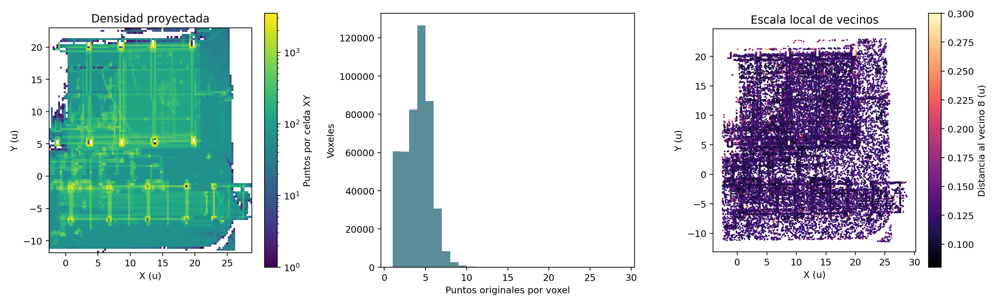

*Densidad proyectada, ocupación de voxeles y escala local de vecinos. La densidad en XY no es una densidad volumétrica de la fábrica.*

In [10]:
mostrar_figura('eda_densidad.png', 'Densidad proyectada, ocupación de voxeles y escala local de vecinos. La densidad en XY no es una densidad volumétrica de la fábrica.')

### Forma local mediante PCA

Queremos saber cómo se distribuyen los puntos vecinos: si forman una superficie, una estructura alargada o una región con dispersión en varias direcciones. PCA resume esas direcciones mediante la covarianza de un vecindario de 20 muestras:

$$C=\frac{1}{k}\sum_{j=1}^{k}(\mathbf{q}_j-\overline{\mathbf{q}})(\mathbf{q}_j-\overline{\mathbf{q}})^T.$$

Sus autovalores ordenados $\lambda_0\leq\lambda_1\leq\lambda_2$ indican la variación en las direcciones principales. Si una dirección tiene poca variación, los puntos pueden estar sobre un plano; si solo una concentra gran variación, la región es alargada. Se calculan:

$$\text{curvatura aproximada}=\frac{\lambda_0}{\lambda_0+\lambda_1+\lambda_2},\qquad
P=\frac{\lambda_1-\lambda_0}{\lambda_2},\qquad
L=\frac{\lambda_2-\lambda_1}{\lambda_2}.$$

Estas medidas dependen de la escala y densidad del vecindario. La curvatura es una aproximación basada en dispersión, no una curvatura diferencial exacta. Ayuda a evitar puentes en uniones complejas; la linealidad también orienta la búsqueda de estructuras esbeltas.

## 6. Segmentación de estructuras grandes

### Intuición de RANSAC

Una superficie extensa puede describirse mediante un plano aunque haya objetos y ruido alrededor. RANSAC propone planos a partir de tres muestras, cuenta cuántos puntos son compatibles y conserva un modelo respaldado por suficientes datos. Los puntos compatibles se llaman inliers. Su distancia al plano es

$$d(\mathbf{x},\Pi)=\frac{|ax+by+cz+d|}{\sqrt{a^2+b^2+c^2}}.$$

Se extraen hasta 18 planos, con tolerancia 0,055 u, 1.200 iteraciones máximas y semilla 42. Además de distancia, se exige que la normal esté a menos de 22° de la del plano. La extracción se detiene si el soporte compatible baja de 700 representantes. Las tolerancias 0,035, 0,055 y 0,08 u se compararon en los experimentos.

Un plano matemático puede contener varias piezas físicamente separadas. Por ello cada soporte se divide por conectividad: DBSCAN con radio 0,22 u y mínimo cuatro muestras; se conservan componentes de al menos 100 representantes para esta etapa. Las menores quedan disponibles para el procesamiento del residuo.

No se identifica piso o cubierta por el orden de RANSAC. Los primeros planos incluyen sectores del piso a distintas cotas; la clasificación combina orientación, posición y extensión. Los modelos siguientes también describen paneles elevados y superficies de la instalación.

In [11]:
planos = pd.DataFrame(leer_json("planes.json"))
display(planos[["step", "support", "model", "centroid", "dimensions", "residual_median"]].rename(columns={
    "step": "Modelo", "support": "Representantes compatibles", "model": "[a,b,c,d]",
    "centroid": "Centro", "dimensions": "Extensiones", "residual_median": "Residuo mediano (u)",
}))

,Modelo,Representantes compatibles,"[a,b,c,d]",Centro,Extensiones,Residuo mediano (u)
0,0,71072,"[-0.0011921897119719247, 0.005790479487590603,...","[13.102511798752321, -0.9317380516191424, -1.6...","[28.368314385414124, 34.22835731506348, 0.2438...",0.014166
1,1,33958,"[7.360249701723208e-05, -0.0034104251306641613...","[12.821402491557473, 11.428996678373933, -1.44...","[26.878739833831787, 32.04301452636719, 0.1910...",0.011555
2,2,13337,"[-0.0018378873894025274, -0.02586679096617196,...","[10.25623546581131, 9.357762969362765, 8.78986...","[20.511109113693237, 11.747298399607342, 0.404...",0.026539
3,3,10838,"[0.002388093206300528, 0.017527083345391693, 0...","[10.432575735644672, 15.580856979309445, 8.795...","[20.526384751001995, 11.668875694274902, 0.311...",0.025115
4,4,4504,"[-0.0020035218731642925, -0.11212593574234225,...","[10.394816201231874, -3.7588243009986124, 2.97...","[22.889919805526734, 27.10307025909424, 3.1027...",0.028876
5,5,7329,"[-0.0008705651788122495, -0.01897716097961572,...","[12.905570481276428, 3.4596537197752175, -1.61...","[28.580995957056682, 32.01487874984741, 0.5705...",0.006182
6,6,4658,"[-0.003199317978685103, 0.00042454858406251365...","[12.064625660746003, -3.903974239290292, 2.931...","[22.919379234313965, 6.86420464515686, 0.17009...",0.030235
7,7,2468,"[-0.002024775502181768, -0.033797235328445946,...","[10.281377401322509, 15.085813538370656, 8.501...","[27.284153819084167, 25.68307517369588, 0.8688...",0.019741
8,8,3087,"[0.05502165944848584, -0.007323246367152214, 0...","[14.284013296069414, 8.002110549294587, -1.152...","[26.92109481493632, 34.37579822540283, 1.50847...",0.021314
9,9,2719,"[0.05708000776647873, -0.012869778155168167, 0...","[19.87233232738043, 7.433818858719291, -1.5580...","[25.615328907966614, 34.223311742146805, 1.434...",0.018934


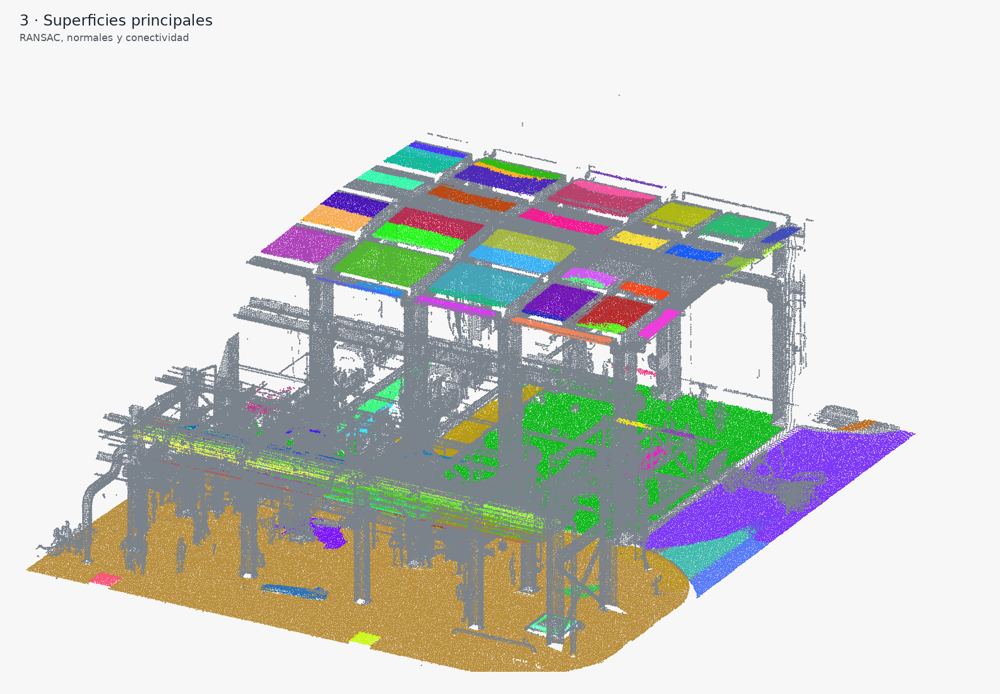

*Planos principales separados por orientación y conectividad. Los puntos que aún no tienen región permanecen visibles en gris.*

In [12]:
mostrar_figura('03_planos.png', 'Planos principales separados por orientación y conectividad. Los puntos que aún no tienen región permanecen visibles en gris.')

## 7. Clustering multietapa

### Agrupamiento espacial con DBSCAN

DBSCAN busca grupos conectados por zonas con suficiente densidad. eps es el radio de vecindad y min_points el mínimo de muestras para que un punto sea núcleo, incluyendo el propio punto. Los puntos sin apoyo pueden quedar como ruido. No se fija de antemano el número de grupos.

Un radio pequeño puede fragmentar superficies; uno grande puede unir objetos que se tocan. El radio no limita el diámetro final del grupo: las cadenas de vecinos pueden extenderse por toda la instalación. La baseline usa dos planos y DBSCAN espacial; sirve para observar esa limitación. En el residuo del método multietapa se muestra una agrupación espacial con eps=0,18 u y mínimo seis.

### Regiones con atributos

La proximidad no basta en esta escena. Para cada punto residual se consideran hasta 19 vecinos distintos del propio punto y se acepta una conexión solo si cumple simultáneamente:

- Distancia espacial ≤0,18 u.
- $|\mathbf{n}_i\cdot\mathbf{n}_j|\geq\cos(28°)$.
- Diferencia RGB normalizado ≤0,40.
- Separación en la dirección normal, o tangencia, ≤0,065 u.
- Curvatura aproximada de ambos puntos <0,15.

Las componentes conexas del grafo forman regiones, y se mantienen las de al menos 25 representantes. El valor absoluto del producto de normales hace que su signo no determine la unión. Los atributos actúan como restricciones con unidades propias, en lugar de mezclarse en una distancia sin ponderación justificada.

El grafo se calcula sobre el mismo residuo usado para el diagnóstico espacial, incorporando más información. No se limita a renombrar las etiquetas de DBSCAN. El radio es un máximo: con un número fijo de vecinos no se incluyen necesariamente todos los puntos dentro de él.

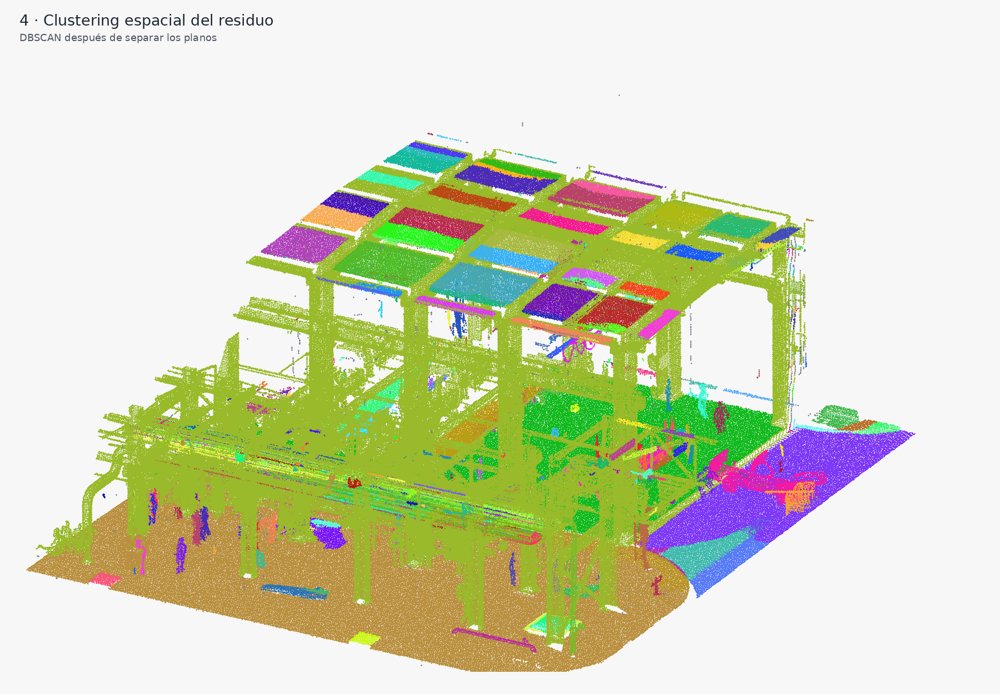

*Agrupamiento espacial del residuo. Aun después de retirar planos pueden persistir regiones que mezclan estructuras en contacto.*

In [13]:
mostrar_figura('04_gruesa.png', 'Agrupamiento espacial del residuo. Aun después de retirar planos pueden persistir regiones que mezclan estructuras en contacto.')

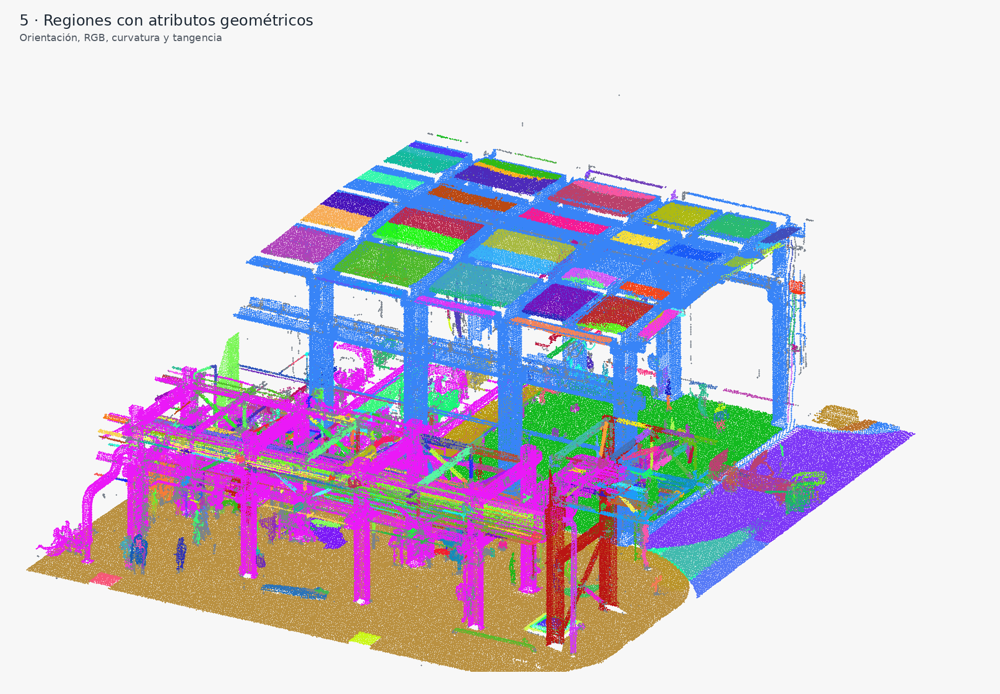

*Regiones obtenidas al añadir normales, RGB, tangencia y curvatura. Todavía pueden aparecer cadenas que atraviesan varios objetos.*

In [14]:
mostrar_figura('05_atributos.png', 'Regiones obtenidas al añadir normales, RGB, tangencia y curvatura. Todavía pueden aparecer cadenas que atraviesan varios objetos.')

## 8. Refinamiento geométrico de regiones

La inspección del agrupamiento con atributos mostró regiones extensas que unían vigas, soportes y redes. Se interviene solo en regiones de más de 15.000 representantes, altura >2,5 u y extensión >3 u en ambas direcciones horizontales. Esta condición excluye los planos delgados del piso.

Un corte horizontal a media altura, de espesor 0,46 u, busca soportes estrechos que persistan en al menos siete de diez intervalos de altura. El resto de cada región se divide por orientación con MiniBatchKMeans: diez grupos, tres inicializaciones, lotes de 4.096 y semilla 42. Los grupos representan orientaciones, no diez objetos. Se usa el tensor $\mathbf{n}\mathbf{n}^T$, invariante al signo, y luego se vuelve a comprobar conectividad con 18° y tangencia 0,04 u.

Se unen caras de un posible soporte solo con esbeltez vertical, proximidad XY, anchura conjunta limitada y solapamiento de altura. Los bordes se recuperan con al menos dos vecinos compatibles de la misma región, sin propagación en cadena. Una búsqueda residual más fina permite componentes de al menos diez representantes.

También se auditan fragmentos menores de 100, 200 y 500 puntos originales. Se consideran contacto, color, normales, ejes y plano conjunto. Se selecciona el límite de 500, con máximo de 2.500 puntos por grupo. Solo se aceptan tres uniones coplanares; la mayor parte de los vecinos se mantiene separada porque cercanía no implica continuidad. En regiones alargadas se exige separación lateral de ejes <0,085 u para evitar unir piezas paralelas distintas.

Las categorías preliminares de piso, cubierta y soporte se protegen durante el refinamiento posterior. Esta precaución conserva separaciones útiles, pero también puede conservar algún error en una intersección. La clasificación definitiva se presenta después de los candidatos cilíndricos.

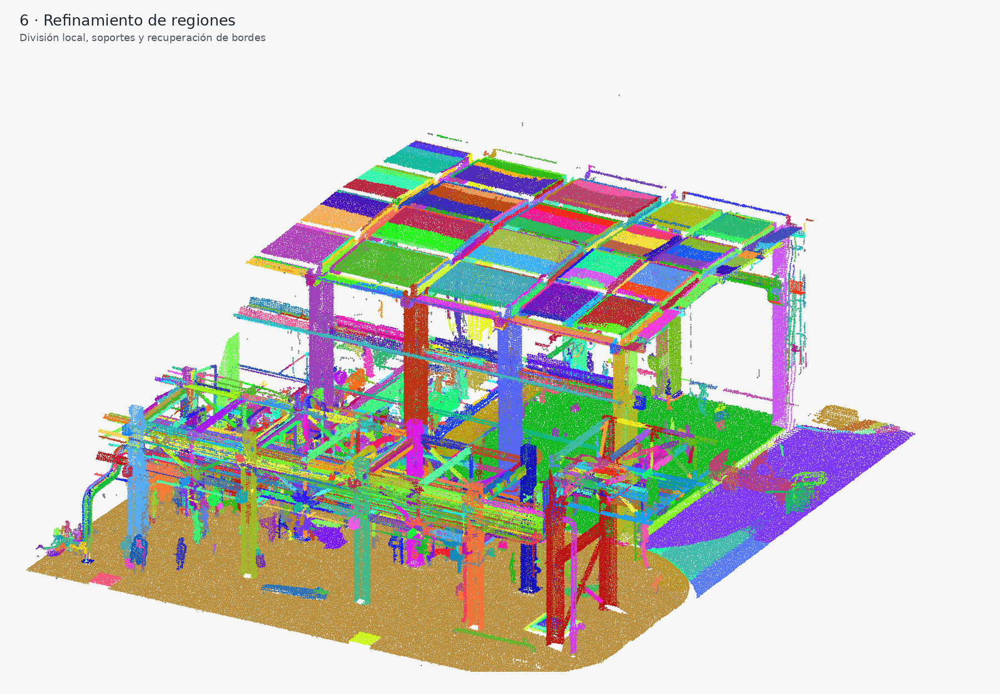

*Refinamiento de regiones: división de zonas extensas, separación de soportes y recuperación local de puntos. Persisten fragmentos en la red de conductos.*

In [15]:
mostrar_figura('06_regiones_refinadas.png', 'Refinamiento de regiones: división de zonas extensas, separación de soportes y recuperación local de puntos. Persisten fragmentos en la red de conductos.')

In [16]:
uniones = pd.read_csv(EXPERIMENTS / "fragment_experiments.csv")
display(uniones[["threshold_original_points", "accepted_edges", "changed_original_points", "n_segments", "seconds"]].rename(columns={
    "threshold_original_points": "Límite de fragmento (puntos)", "accepted_edges": "Uniones aceptadas",
    "changed_original_points": "Puntos con cambio de ID", "n_segments": "Regiones", "seconds": "Tiempo de etapa (s)",
}))

,Límite de fragmento (puntos),Uniones aceptadas,Puntos con cambio de ID,Regiones,Tiempo de etapa (s)
0,100,2,133,1979,0.041531
1,200,2,133,1979,0.057924
2,500,3,360,1978,0.093602


## 9. Refinamiento de conductos cilíndricos

### Por qué una estructura alargada no es necesariamente una tubería

Una viga, una baranda y una conducción pueden tener linealidad alta. Además, un ajuste cilíndrico puede explicar solo franjas o esquinas de un perfil estructural. Los primeros controles con distancia radial y normales aceptaron algunos perfiles en U, aun cuando parecían adecuados por residuo parcial. Por eso se descartaron como criterio suficiente para etiquetar.

La comparación de secciones de los puntos originales permite reconocer perfiles en U, en I y arcos circulares. El método seleccionado exige explicar el componente transversal completo, no únicamente una franja de inliers.

### Ajuste de perfiles y extensión del eje

En la red frontal, los conductos observados siguen aproximadamente X. Se inspeccionan secciones en X=5, 11 y 17 u, con semiespesor 0,35 u. DBSCAN 2D agrupa las muestras proyectadas con radio 0,052 u y mínimo tres. Para cada componente suficiente se ajusta un círculo con centro $(a,b)$ y radio $r$:

$$e_j=\left|\sqrt{(y_j-a)^2+(z_j-b)^2}-r\right|.$$

Se admite un radio entre 0,055 y 0,55 u, más del 90% del componente con residuo <0,022 u, p95 <0,028 u y arco observado ≥115°. El ajuste usa mínimos cuadrados con pérdida robusta soft_l1, que reduce la influencia de residuos grandes sin eliminarlos automáticamente. Después se ajustan el centro, dos inclinaciones del eje y el radio en 3D.

La extensión se comprueba en cinco posiciones distribuidas a lo largo del eje, usando puntos originales. Deben existir al menos cuatro secciones y pasar al menos tres, con soporte ≥86%, p95 <0,035 u y arco ≥110°. La variación de radios entre secciones debe ser <0,018 u. Estas comprobaciones evalúan consistencia geométrica en el mismo escaneo; no son un conjunto de prueba semántico independiente.

Los modelos repetidos del mismo eje se deduplican. Se transfieren puntos con residuo radial <0,025 u y normales compatibles. Un hueco axial >0,45 u produce otra instancia. La operación se limita al volumen frontal realmente estudiado, no a toda la fábrica.

La clase conduccion_cilindrica_candidata describe la evidencia circular y la compatibilidad con una conducción; no confirma que transporte fluidos. Los perfiles estructurales que no cumplen los criterios conservan sus categorías geométricas o unknown.

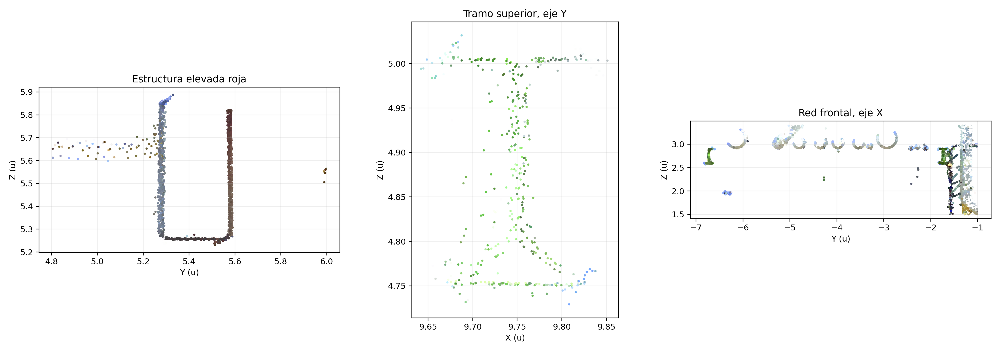

*Secciones de los puntos originales: perfil elevado en U, perfil en I y arcos circulares de la red frontal. Permiten detectar errores de un ajuste parcial.*

In [17]:
mostrar_figura('secciones_originales.png', 'Secciones de los puntos originales: perfil elevado en U, perfil en I y arcos circulares de la red frontal. Permiten detectar errores de un ajuste parcial.')

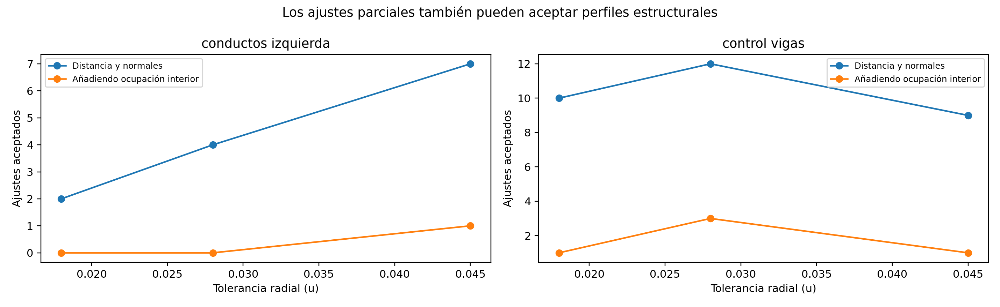

*Los ajustes parciales aceptan también elementos estructurales. Aumentar el número de ajustes aceptados no equivale a identificar mejor las conducciones.*

In [18]:
mostrar_figura('experimentos_cilindros.png', 'Los ajustes parciales aceptan también elementos estructurales. Aumentar el número de ajustes aceptados no equivale a identificar mejor las conducciones.')

In [19]:
modelos_cilindricos = leer_json("cylinder_models.json")
tabla_cilindros = pd.DataFrame([{ 
    "Propuesta": modelo["proposal_id"], "Radio (u)": modelo["radius"],
    "Longitud observada (u)": modelo["length"], "Secciones que pasan": modelo["profile_passed"],
    "Secciones comprobadas": modelo["profile_tested"], "Instancias": modelo["instance_ids"],
} for modelo in modelos_cilindricos])
display(tabla_cilindros.round(5))
residuos_originales = pd.read_csv(METRICS / "cylinder_original_geometry.csv")
display(residuos_originales[["instance_id", "n_original_points", "radius", "p50_radial_original", "p95_radial_original", "profile_passed", "profile_tested"]].round(5))

,Propuesta,Radio (u),Longitud observada (u),Secciones que pasan,Secciones comprobadas,Instancias
0,12,0.20405,21.94065,4,5,[1999]
1,7,0.11036,22.05847,4,5,[2000]
2,9,0.20494,21.06453,4,5,[2001]
3,3,0.11041,19.95229,3,5,[2002]
4,1,0.16369,8.69059,3,5,[2003]
5,6,0.11124,22.12651,3,5,[2004]
6,4,0.11243,22.15717,3,5,[2005]


,instance_id,n_original_points,radius,p50_radial_original,p95_radial_original,profile_passed,profile_tested
0,1999,8079,0.20405,0.00268,0.01648,4,5
1,2000,2956,0.11036,0.00237,0.01991,4,5
2,2001,6328,0.20494,0.00465,0.01986,4,5
3,2002,2349,0.11041,0.00297,0.01850,3,5
4,2003,1708,0.16369,0.00180,0.01706,3,5
5,2004,2881,0.11124,0.00303,0.02114,3,5
6,2005,2565,0.11243,0.00579,0.02375,3,5


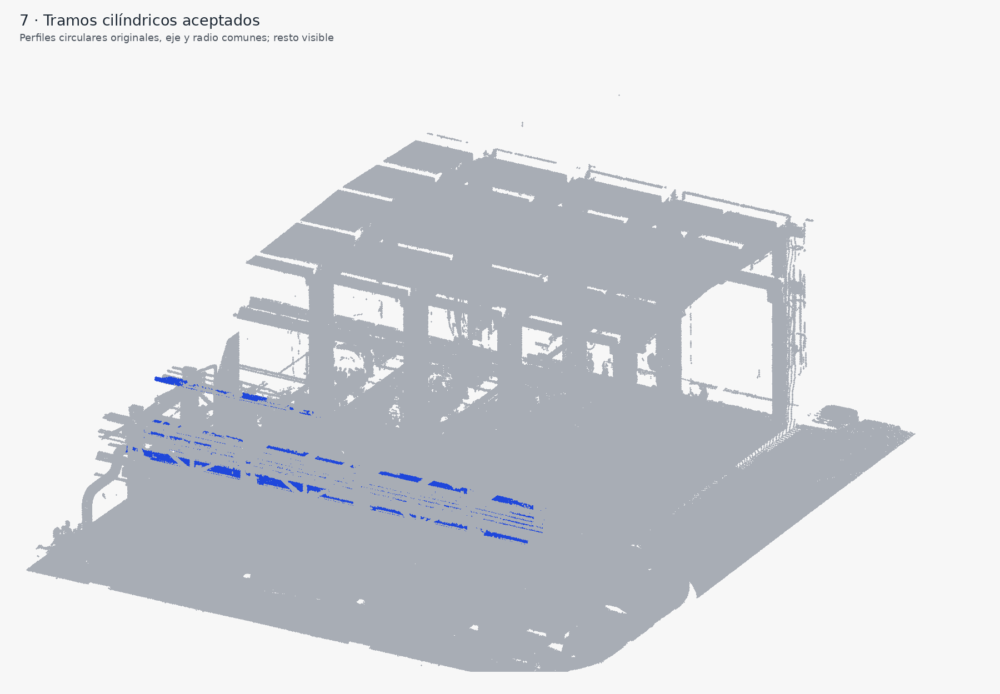

*Siete tramos aceptados resaltados sobre la nube completa. Cada modelo debe cumplir las pruebas de perfil y continuidad.*

In [20]:
mostrar_figura('07_cilindros.png', 'Siete tramos aceptados resaltados sobre la nube completa. Cada modelo debe cumplir las pruebas de perfil y continuidad.')

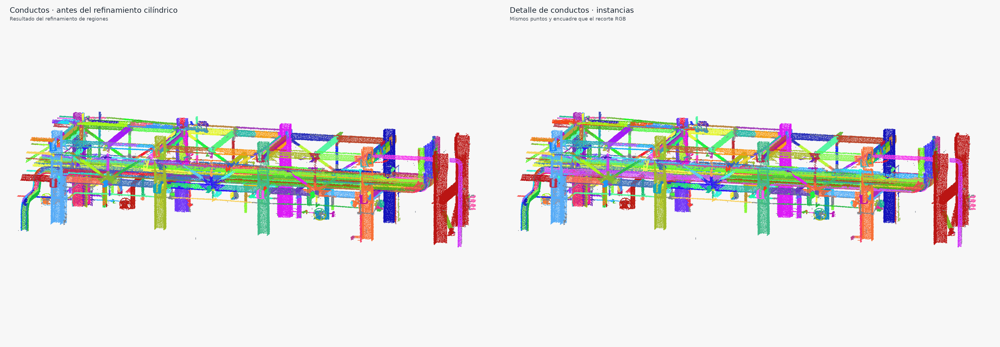

*Red frontal antes y después del refinamiento cilíndrico. Se comparan exactamente los mismos puntos con cámara fija.*

In [21]:
mostrar_figura('refinamiento_conductos.png', 'Red frontal antes y después del refinamiento cilíndrico. Se comparan exactamente los mismos puntos con cámara fija.')

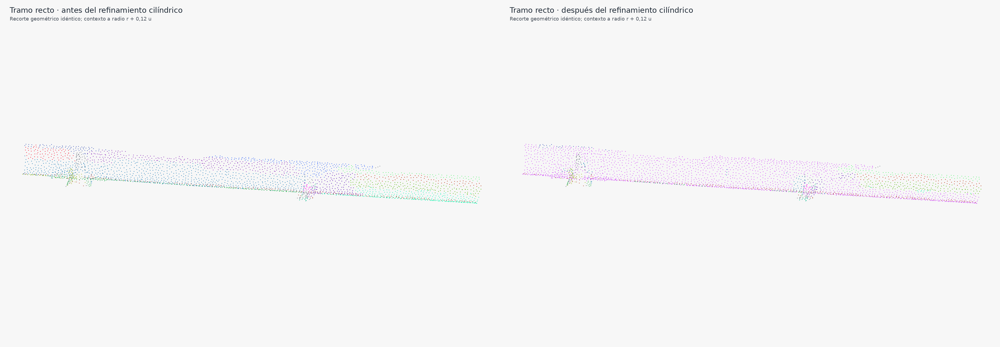

*Acercamiento de un tramo: se observa mayor continuidad del ID, aunque permanecen puntos de contexto y fronteras imperfectas.*

In [22]:
mostrar_figura('refinamiento_tubo.png', 'Acercamiento de un tramo: se observa mayor continuidad del ID, aunque permanecen puntos de contexto y fronteras imperfectas.')

## 10. Experimentos y selección de parámetros

Las comparaciones registradas permiten explicar la configuración elegida. La baseline mantiene dos planos y varía el radio y la densidad de DBSCAN. Se comparan tres tolerancias de RANSAC, tres ángulos de normales y tres restricciones RGB, cambiando un aspecto relevante por ensayo. No se realizó una búsqueda exhaustiva ni se escogió el resultado solo por tener más regiones o menos ruido.

La baseline de referencia, con eps=0,16 u y mínimo seis, agrupa el 74,69% de toda la nube en una sola región. Su cobertura alta oculta una fusión importante. Al aumentar el radio, ese grupo crece. En el grafo de atributos, permitir 40° vuelve a conectar gran parte de la estructura; 18° aumenta la fragmentación. Se seleccionaron 28° y diferencia RGB 0,40 como compromiso, seguido del refinamiento geométrico.

Las tolerancias pequeñas de RANSAC conservan superficies más estrictas, pero fragmentan el soporte; las grandes pueden engrosar planos y recoger piezas cercanas. Se conservó 0,055 u. En los ensayos cilíndricos, el control de perfil completo permitió descartar ajustes que solo describían una parte de una viga. El criterio final se apoya en la forma observada, no en maximizar la cantidad de tubos detectados.

Los conteos y porcentajes se ponderan a los puntos originales. Los tiempos corresponden a las etapas indicadas y excluyen renderizado; algunos cálculos comparten planos o preprocesamiento. Por ello no se deben sumar todos los ensayos alternativos como si fueran un único procesamiento.

In [23]:
experimentos = pd.read_csv(EXPERIMENTS / "clustering.csv")
display(experimentos[["experiment", "n_segments", "unknown_pct", "largest_pct", "size_median", "seconds"]].rename(columns={
    "experiment": "Configuración", "n_segments": "Regiones", "unknown_pct": "Sin instancia (%)",
    "largest_pct": "Grupo mayor (%)", "size_median": "Tamaño mediano", "seconds": "Tiempo de etapa (s)",
}).round(3))

,Configuración,Regiones,Sin instancia (%),Grupo mayor (%),Tamaño mediano,Tiempo de etapa (s)
0,baseline_e0.12_m6,719,0.970,70.100,25.0,17.808
1,baseline_e0.16_m6,400,0.352,74.687,31.0,13.746
2,baseline_e0.20_m6,274,0.168,75.725,27.0,16.155
3,baseline_e0.16_m12,677,2.696,68.646,49.0,14.878
4,planes_t0.035,75,62.077,12.297,3249.0,84.193
5,planes_t0.055,93,61.092,14.801,1485.0,97.061
6,planes_t0.080,88,58.290,18.541,1553.5,67.479
7,coarse,515,0.349,56.213,49.0,2.699
8,regions_a18_c0.40,710,10.238,22.038,215.0,2.682
9,regions_a28_c0.40,525,8.995,22.747,228.0,2.801


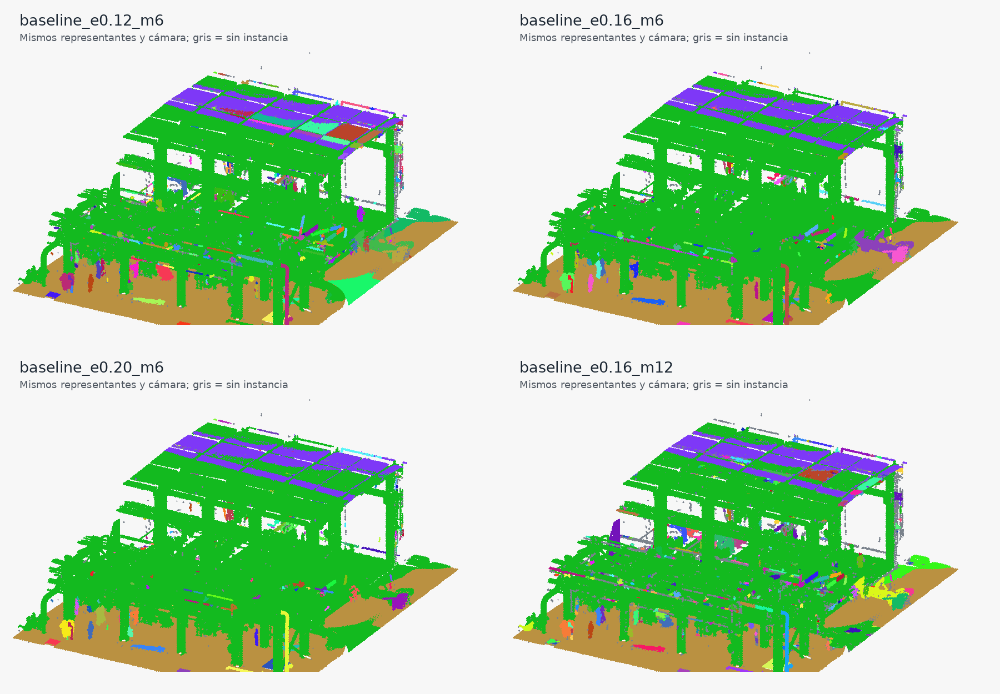

*Comparación de radios 0,12/0,16/0,20 u y mínimos 6/12. Los colores muestran que la gran región fusionada persiste en la baseline.*

In [24]:
mostrar_figura('experimentos_dbscan.png', 'Comparación de radios 0,12/0,16/0,20 u y mínimos 6/12. Los colores muestran que la gran región fusionada persiste en la baseline.')

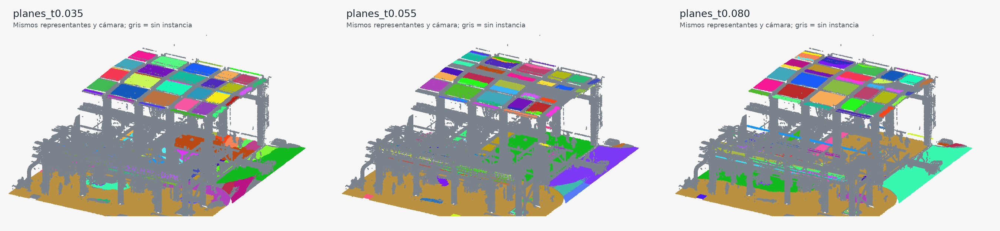

*Tolerancias 0,035, 0,055 y 0,08 u. El gris corresponde al residuo disponible para las siguientes etapas.*

In [25]:
mostrar_figura('experimentos_ransac.png', 'Tolerancias 0,035, 0,055 y 0,08 u. El gris corresponde al residuo disponible para las siguientes etapas.')

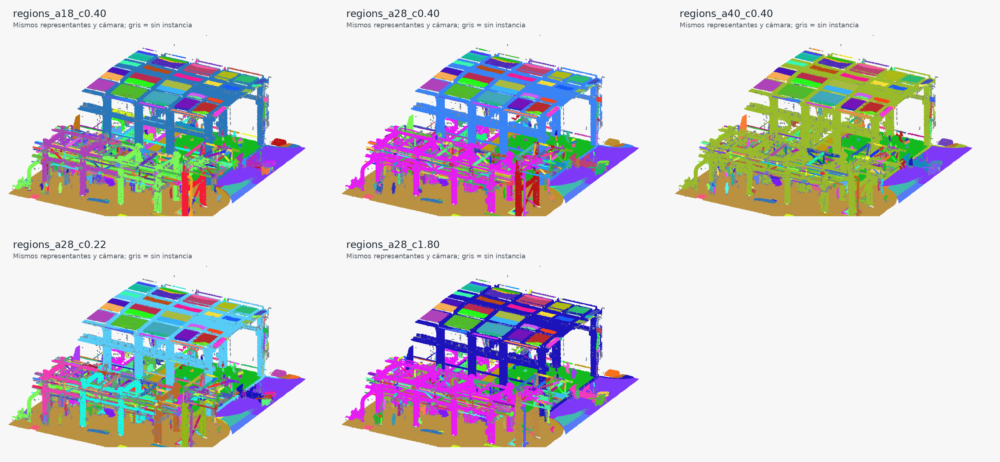

*Restricciones de normales y RGB. La diferencia RGB 1,80 elimina de hecho el límite de color, pues supera su distancia máxima posible.*

In [26]:
mostrar_figura('experimentos_atributos.png', 'Restricciones de normales y RGB. La diferencia RGB 1,80 elimina de hecho el límite de color, pues supera su distancia máxima posible.')

In [27]:
controles = pd.read_csv(EXPERIMENTS / "cylinder_controls.csv")
display(controles[["experiment", "crop", "threshold", "n_seed_fits", "accepted_models", "fit_seconds"]].rename(columns={
    "experiment": "Control", "crop": "Recorte", "threshold": "Tolerancia radial (u)",
    "n_seed_fits": "Semillas probadas", "accepted_models": "Ajustes aceptados", "fit_seconds": "Tiempo de ajuste (s)",
}).round(4))

,Control,Recorte,Tolerancia radial (u),Semillas probadas,Ajustes aceptados,Tiempo de ajuste (s)
0,radial_normales,conductos_derecha,0.018,28,4,1.0161
1,radial_normales,conductos_derecha,0.028,28,8,0.7607
2,radial_normales,conductos_derecha,0.045,28,9,0.8848
3,radial_normales,conductos_izquierda,0.018,28,2,0.6390
4,radial_normales,conductos_izquierda,0.028,28,4,0.7912
5,radial_normales,conductos_izquierda,0.045,28,7,0.9781
6,radial_normales,control_vigas,0.018,28,10,1.0031
7,radial_normales,control_vigas,0.028,28,12,1.0850
8,radial_normales,control_vigas,0.045,28,9,1.0940
9,ocupacion_interior,conductos_derecha,0.018,28,0,0.8509


## 11. Resultados de segmentación

La salida definitiva contiene 1.967 regiones, conserva los 1.647.021 puntos originales y mantiene la correspondencia de índices. El 97,080% de los puntos tiene instancia y el 2,920% queda sin instancia. El grupo mayor representa el 14,963% y corresponde al sector principal del piso.

La categoría semántica unknown reúne 427.058 puntos (25,929%). Esta cifra incluye puntos con instancia cuya identidad es ambigua; no equivale a los 48.091 puntos sin instancia. La clasificación reconoce parcialmente piso, cubierta, superficies planas, soportes, elementos lineales y conducciones cilíndricas candidatas.

Los siete tramos cilíndricos contienen 26.866 puntos originales. La distancia radial p95 de cada tramo sobre las coordenadas originales es menor de 0,024 u. Algunas regiones que antes compartían puntos de varios ejes cilíndricos se separan por eje y radio, mientras otras piezas fuera del volumen estudiado conservan las etiquetas del refinamiento general.

In [28]:
resumen_resultado = pd.DataFrame({
    "Métrica": ["Puntos originales", "Regiones", "Con instancia (%)", "Sin instancia (puntos)", "Sin instancia (%)", "Unknown semántico (puntos)", "Unknown semántico (%)", "Grupo mayor (%)"],
    "Valor": [resultado["n_points"], resultado["n_segments"], resultado["coverage_pct"], resultado["unknown_points"], resultado["unknown_pct"], resultado["semantic_unknown_points"], resultado["semantic_unknown_pct"], resultado["largest_pct"]],
})
display(resumen_resultado)
display(clases.round(4))
display(segmentos.nlargest(12, "n_points")[["segment_id", "n_points", "dimension_x", "dimension_y", "dimension_z", "linearity", "planarity", "semantic", "justification"]])

,Métrica,Valor
0,Puntos originales,1.647021e+06
1,Regiones,1.967000e+03
2,Con instancia (%),9.708012e+01
3,Sin instancia (puntos),4.809100e+04
4,Sin instancia (%),2.919878e+00
5,Unknown semántico (puntos),4.270580e+05
6,Unknown semántico (%),2.592912e+01
7,Grupo mayor (%),1.496259e+01


,class_id,semantic,n_points,pct
0,0,unknown,427058,25.9291
1,1,piso,446570,27.1138
2,2,cubierta_superior,88100,5.3491
3,3,superficie_plana,112379,6.8232
4,4,soporte_vertical_candidato,186050,11.2962
5,5,elemento_lineal_candidato,359998,21.8575
6,6,conduccion_cilindrica_candidata,26866,1.6312


,segment_id,n_points,dimension_x,dimension_y,dimension_z,linearity,planarity,semantic,justification
1,0,246437,28.377139,14.962652,0.407923,0.743293,0.256698,piso,Superficie horizontal extensa próxima a cota b...
3,2,125790,22.699242,16.330441,0.299308,0.483010,0.516984,piso,Superficie horizontal extensa próxima a cota b...
0,-1,48091,31.053051,34.826904,16.770250,0.182297,0.699118,unknown,Evidencia insuficiente; región o ruido sin cla...
2,1,40661,5.492693,17.723765,0.226904,0.882539,0.117450,piso,Superficie horizontal extensa próxima a cota b...
35,34,22747,22.469884,3.599089,0.288644,0.989451,0.010543,piso,Superficie horizontal extensa próxima a cota b...
989,1016,22446,1.105049,1.360173,10.301241,0.983052,0.005216,soporte_vertical_candidato,Región vertical esbelta y alta; posible soport...
990,1017,21863,1.047745,1.354941,10.263274,0.982415,0.006210,soporte_vertical_candidato,Región vertical esbelta y alta; posible soport...
479,482,21422,4.207848,5.748692,9.702376,0.306255,0.665815,unknown,Geometría ambigua; no se infiere identidad del...
987,1014,20803,1.168419,1.355226,10.282235,0.983950,0.004097,soporte_vertical_candidato,Región vertical esbelta y alta; posible soport...
1074,1102,14199,1.037695,1.519830,10.295165,0.971543,0.020110,unknown,Geometría ambigua; no se infiere identidad del...


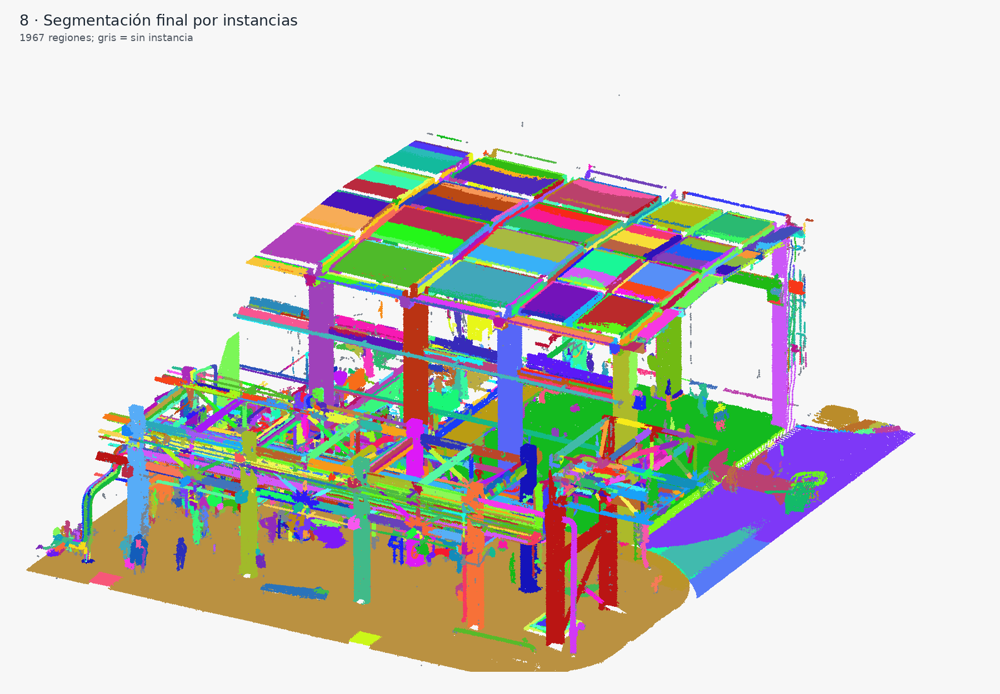

*Resultado definitivo por regiones. Los colores codifican IDs y no representan categorías semánticas.*

In [29]:
mostrar_figura('08_instancias.png', 'Resultado definitivo por regiones. Los colores codifican IDs y no representan categorías semánticas.')

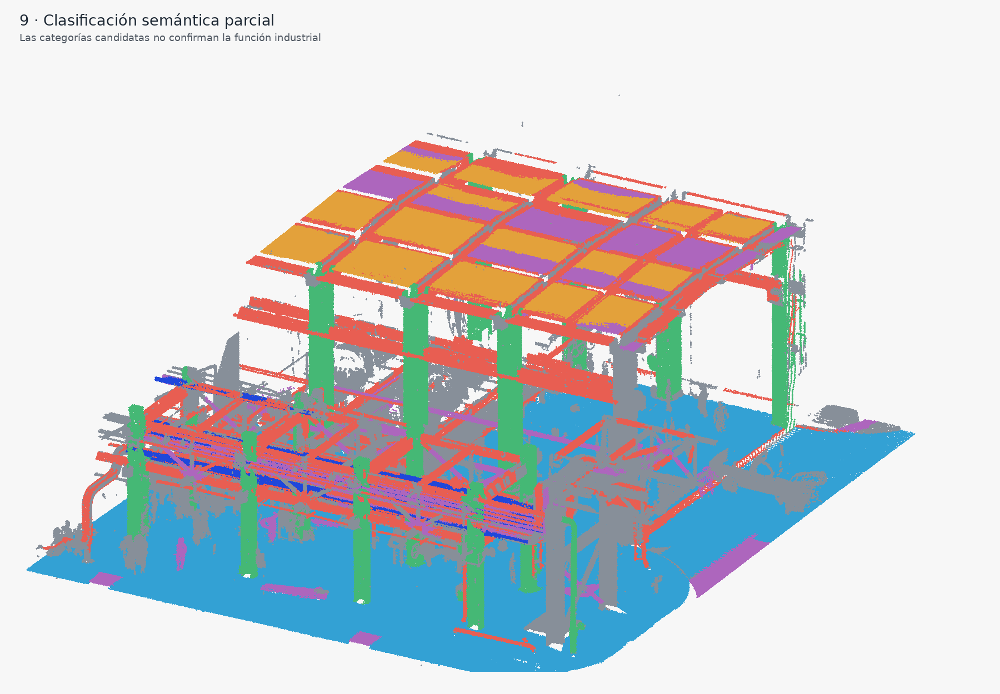

*Resultado definitivo por categorías. Las superficies y conducciones candidatas se interpretan con el alcance descrito en el método.*

In [30]:
mostrar_figura('09_clases.png', 'Resultado definitivo por categorías. Las superficies y conducciones candidatas se interpretan con el alcance descrito en el método.')

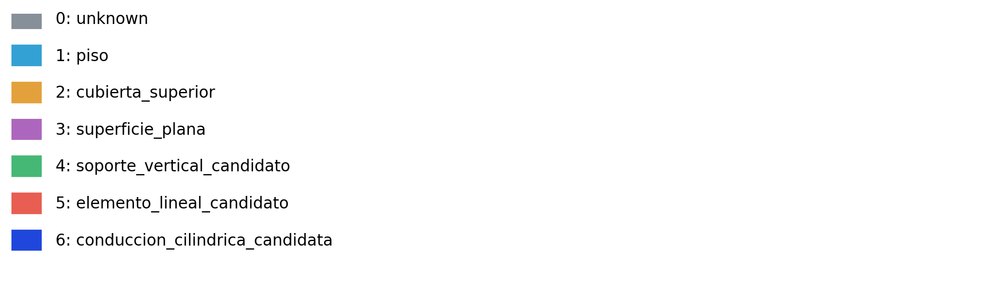

*Correspondencia de IDs de clase y colores. La categoría unknown se conserva cuando la evidencia es insuficiente.*

In [31]:
mostrar_figura('leyenda_clases.png', 'Correspondencia de IDs de clase y colores. La categoría unknown se conserva cuando la evidencia es insuficiente.')

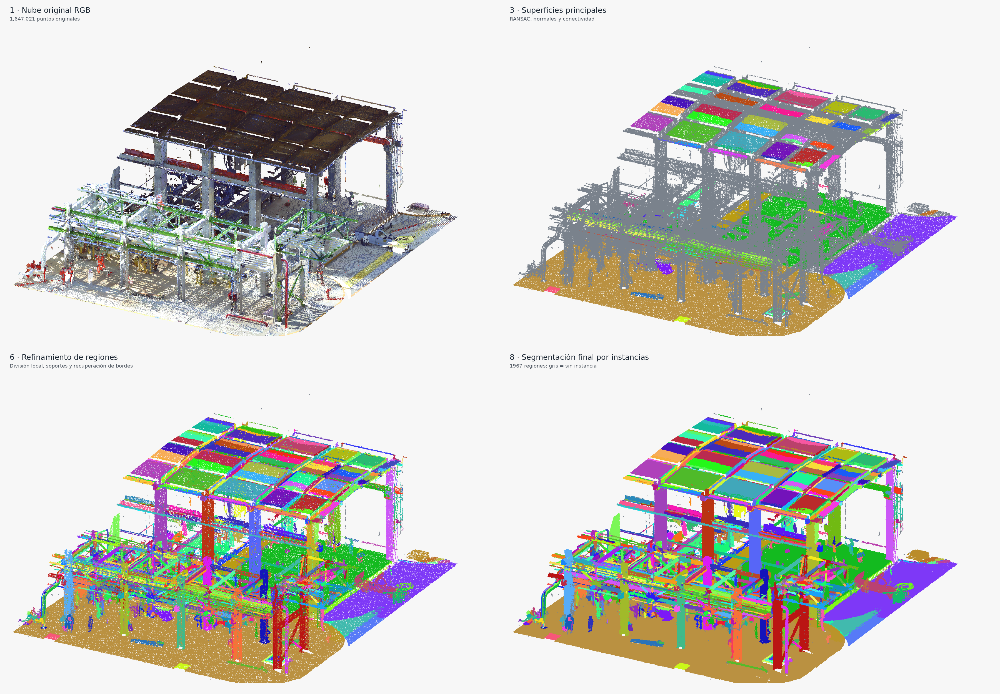

*Original, planos, refinamiento de regiones y resultado definitivo. Las cuatro vistas usan la misma cámara, orientación y escala.*

In [32]:
mostrar_figura('comparativa_etapas.png', 'Original, planos, refinamiento de regiones y resultado definitivo. Las cuatro vistas usan la misma cámara, orientación y escala.')

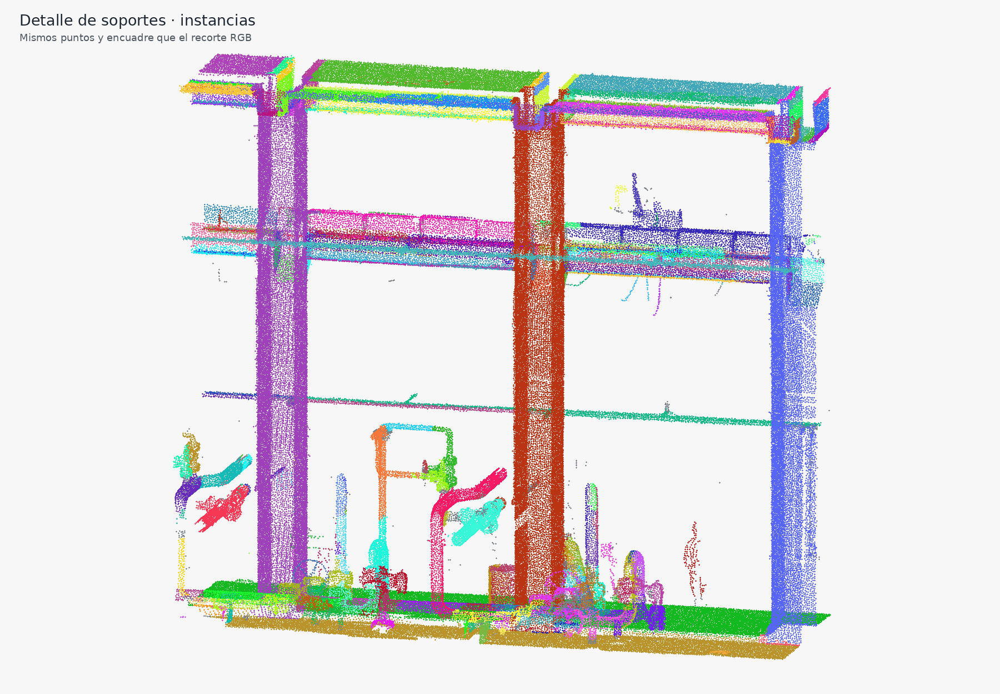

*Acercamiento de los soportes. Las categorías estructurales protegidas mantienen sus IDs durante el ajuste cilíndrico.*

In [33]:
mostrar_figura('detalle_soportes_instancias.png', 'Acercamiento de los soportes. Las categorías estructurales protegidas mantienen sus IDs durante el ajuste cilíndrico.')

## 12. Evaluación y discusión sin ground truth

No contamos con etiquetas de referencia por punto. Por tanto, no podemos reportar accuracy, precision, recall ni IoU semántica: no existe una clasificación correcta conocida con la que comparar la salida. Tampoco se interpreta la inspección visual como una medición de esas métricas.

Se utilizaron cantidad de regiones, cobertura de instancias, porcentaje sin instancia, puntos unknown, tamaños de regiones y tiempos. La coherencia geométrica se comprobó mediante orientación, conectividad, residuos de plano y de cilindro, estabilidad del radio y perfiles observados en distintas posiciones. Las figuras permiten analizar fusiones y fragmentaciones en el mismo encuadre.

La cobertura mide cuánto se asignó, no cuánto se acertó. El tamaño del grupo mayor revela fusiones potenciales, pero un piso extenso puede ser correctamente grande. La cantidad de regiones tampoco es una medida de calidad: separar cada punto produciría muchos grupos y sería poco útil.

El refinamiento final mejora la continuidad en los tramos comprobados, pero no reduce uniformemente la fragmentación. Las regiones menores de 100 puntos pasan de 616 a 621 y quedan siete restos de regiones antes mayores. Esta limitación se conserva en la evaluación; no se oculta tras la reducción del total de regiones. Los 720.720 puntos con categorías preliminares de piso, cubierta o soporte mantienen sus clases e instancias.

La comparación sobre el soporte de cada cilindro muestra cuántos IDs anteriores atravesaban el mismo tramo. Su concentración después de unirlos depende de la operación aplicada y es descriptiva; la justificación geométrica adicional proviene de los perfiles originales y sus residuos.

In [34]:
etapas_refinamiento = pd.read_csv(METRICS / "refinement_stages.csv")
display(etapas_refinamiento[["stage", "n_segments", "coverage_pct", "semantic_unknown_points", "regions_lt100", "regions_lt200", "regions_lt500"]].round(4))
display(pd.read_csv(METRICS / "small_remainders.csv"))

,stage,n_segments,coverage_pct,semantic_unknown_points,regions_lt100,regions_lt200,regions_lt500
0,region_refinement,1981,97.0714,437384,616,1005,1502
1,cylinder_refinement,1967,97.0801,427058,621,1003,1488


,id,before_points,after_points
0,714,262,68
1,856,184,61
2,863,528,57
3,868,1263,90
4,878,148,50
5,881,299,41
6,883,356,64


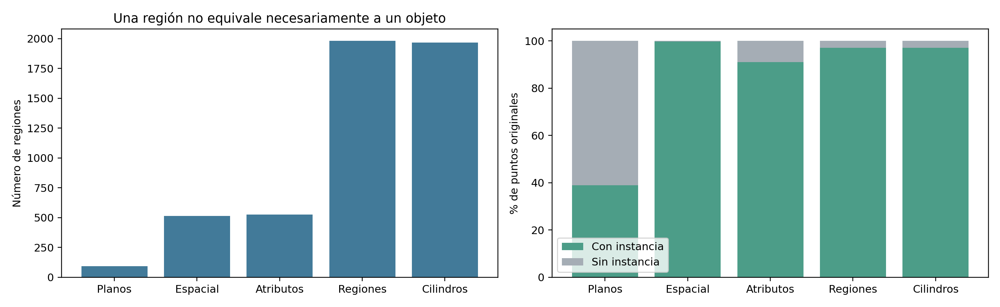

*Número de regiones y cobertura ponderada al original. El aumento de cobertura o regiones tiene que interpretarse junto con su forma y las posibles fusiones.*

In [35]:
mostrar_figura('metricas_etapas.png', 'Número de regiones y cobertura ponderada al original. El aumento de cobertura o regiones tiene que interpretarse junto con su forma y las posibles fusiones.')

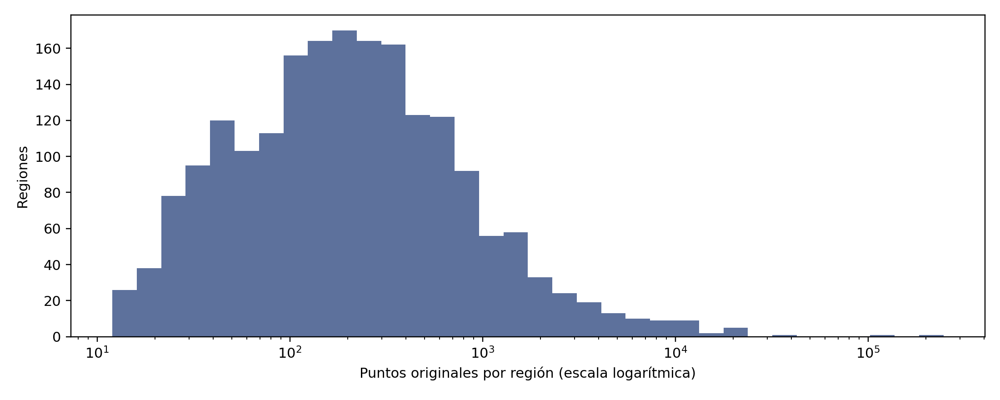

*Distribución final de tamaños, con escala logarítmica en el número de puntos por región.*

In [36]:
mostrar_figura('tamanos_segmentos.png', 'Distribución final de tamaños, con escala logarítmica en el número de puntos por región.')

## 13. Limitaciones

Persisten caras de un mismo objeto con distintos IDs, piezas coplanares en contacto y regiones pequeñas en equipos complejos. La conectividad puede atravesar una transición suave de normales, mientras un umbral estricto puede dividir una superficie curva. El color es sensible al brillo y a sombras.

Los cilindros se verifican en una zona frontal y con una dirección principal observada. El procedimiento no pretende detectar todos los tubos de la fábrica ni resolver codos, válvulas o ramificaciones. Dos tramos colineales de igual radio y poca separación podrían seguir siendo objetos distintos; el límite de hueco reduce esa posibilidad, sin eliminarla.

La protección de estructuras conserva las separaciones útiles, pero puede mantener errores cerca de una intersección. Las normales se comparan en los representantes y algunas normales originales del mismo voxel son menos compatibles. La comprobación geométrica de los puntos originales se informa por separado.

La transferencia por voxel mantiene las filas originales, pero no permite separar detalles que ya se promediaron en el mismo cubo. Los umbrales pertenecen a este dataset y sus unidades. Las clases candidatas describen evidencia geométrica: una superficie cilíndrica no demuestra la función de una conducción, y un elemento lineal no demuestra que sea una viga.

## 14. Conclusiones

La combinación de superficies principales, agrupamiento con atributos y refinamiento local permitió obtener una segmentación interpretable de la instalación. Los planos y su conectividad separan las superficies extensas; las normales, el color y la geometría local aportan información para las regiones restantes.

El estudio de los conductos mostró que un buen ajuste parcial no basta para reconocer una estructura cilíndrica. Exigir perfiles completos y consistencia de eje y radio permitió consolidar siete tramos, conservando las separaciones estructurales protegidas. Los experimentos también muestran por qué no conviene elegir parámetros solo por cobertura o cantidad de grupos.

El resultado conserva todos los puntos e índices originales y ofrece una clasificación parcial justificable. Las principales limitaciones son la fragmentación residual, los contactos ambiguos y el alcance local del ajuste cilíndrico. Mantener unknown y distinguir candidatos de categorías confirmadas hace que la interpretación sea más prudente y coherente con los datos disponibles.